# Sesión de clase 14 · Integración: el asistente de la Tienda Virtual

**Contexto:** se conectan todas las piezas. Un agente con un LLM local (Qwen 2.5, 0.5B) se conecta
como **cliente MCP** al server del Ejercicio 3, que a su vez usa el **RAG** del Ejercicio 1, la
**ontología y el RAG determinista** del Ejercicio 2 y la **API en vivo** de la tienda.

```mermaid
graph LR
  U[Usuario] --> AG["Agente<br/>(Qwen 0.5B + router)"]
  AG -- "cliente MCP · stdio" --> S["MCP server<br/>tienda-virtual"]
  S --> T1[buscar_productos<br/>buscar_resenas]
  S --> T2[consultar_ontologia]
  S --> T3[stock_en_vivo<br/>ordenes_cliente]
  T1 --> B[(bdv · ChromaDB<br/>Ejercicio 1)]
  T2 --> O[(ontología RDF<br/>Ejercicio 2)]
  T3 --> A[API REST<br/>Tienda Virtual]
  B -.-> D[(datos scrapeados)]
  O -.-> D
```

Con un modelo tan pequeño el punto débil es el **tool-calling**: elegir la herramienta correcta y
pasarle argumentos válidos. Este notebook mide el problema y aplica estrategias para hacerlo fiable.

**Requisitos:** ejercicios 1–3 ejecutados y la Tienda Virtual levantada.

**Etapas:** agente ingenuo · modos de falla · estrategias de fiabilidad · agente robusto ·
**comparación ingenuo vs. robusto** · **tablero final de todas las configuraciones** · experimentación.

## Configuración

In [1]:
import os, warnings
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"; os.environ["TOKENIZERS_PARALLELISM"] = "false"
warnings.filterwarnings("ignore")
import inspect, sys, time
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import requests
import torch
import transformers; transformers.logging.set_verbosity_error()
from transformers import AutoTokenizer, AutoModelForCausalLM

sys.path.append(".."); sys.path.insert(0, "../mcp_tienda")
import comparacion as cmp
from agente import AgenteTienda, mostrar_traza

MODELO_LLM = "Qwen/Qwen2.5-0.5B-Instruct"
print("Tienda:", requests.get("http://localhost:3000/api/health", timeout=5).json()["status"])

tokenizer = AutoTokenizer.from_pretrained(MODELO_LLM)
llm = AutoModelForCausalLM.from_pretrained(MODELO_LLM, dtype=torch.float32); llm.eval()
banco = cmp.cargar_banco()

Tienda: ok


W1124 17:35:26.931000 34989 .venv/lib/python3.11/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


## 1. Agente ingenuo

La estrategia estándar: el LLM recibe **las 5 tools** que publica el server, decide cuál llamar, se
ejecuta la llamada tal cual la escribió y el LLM redacta la respuesta final con el resultado. Con un
modelo grande esto suele bastar.

In [2]:
ingenuo = AgenteTienda(llm, tokenizer, estrategia="ingenua")
print("Tools descubiertas:", await ingenuo.conectar())

for p in ["¿Cuál es el precio del Nintendo Switch OLED?",
          "¿Cuál es la calificación promedio de los productos de la categoría Audio?",
          "¿Qué país tiene el mayor monto total de ventas?"]:
    mostrar_traza(await ingenuo.preguntar(p))

Tools descubiertas: ['buscar_productos', 'buscar_resenas', 'consultar_ontologia', 'stock_en_vivo', 'ordenes_cliente']
❓ ¿Cuál es el precio del Nintendo Switch OLED?
   · llm                  {"salida": "<tool_call>\n{\"name\": \"buscar_productos\", \"arguments\": {\"consulta\": \"Nintendo Switch OLED\", \"categoria\": \"Electrodomésticos\", \"precio_max\": 50}}\n</tool
   · call_tool            {"tool": "buscar_productos", "args": {"consulta": "Nintendo Switch OLED", "categoria": "Electrodomésticos", "precio_max": 50}, "error_mcp": false, "resultado": "[]"}
🤖 No se encontraron productos relacionados con el Nintendo Switch OLED en la búsqueda realizada.  (7.81 s)

❓ ¿Cuál es la calificación promedio de los productos de la categoría Audio?
   · llm                  {"salida": "<tool_call>\n{\"name\": \"buscar_productos\", \"arguments\": {\"consulta\": \"Audio\", \"categoria\": \"Producto\", \"precio_max\": null}}\n</tool_call>"}
   · call_tool            {"tool": "buscar_productos", "arg

## 2. Modos de falla de un modelo pequeño

En las trazas aparecen los errores típicos de tool-calling:

| Falla | Ejemplo observado |
|---|---|
| **Tool equivocada** | usa `buscar_productos` (semántico) para un promedio, o `ordenes_cliente` para ventas por país |
| **Argumentos inventados** | `precio_max: 50` o `categoria: "Electrodomésticos"` que no estaban en la pregunta y vacían el resultado |
| **No llama ninguna tool** | responde de memoria o pide más detalles |
| **JSON mal formado** | comillas simples, comas sobrantes, sin `<tool_call>` |
| **Reescritura del resultado** | recibe el dato correcto y lo resume mal |

## 3. Estrategias de fiabilidad

El agente robusto (`mcp_tienda/agente.py`) combina siete técnicas. Ninguna requiere un modelo más
grande; todas trasladan decisiones del LLM a código determinista o restringen lo que el LLM puede
hacer mal.

| # | Técnica | Qué ataca |
|---|---|---|
| 1 | **Pre-router determinista** (intenciones del Ejercicio 2): si reconoce la intención, llama `consultar_ontologia` o `stock_en_vivo` **sin pasar por el LLM** | tool equivocada en preguntas exactas |
| 2 | **Menos tools y *few-shot***: cuando decide el LLM, solo ve `buscar_productos` y `buscar_resenas`, con dos ejemplos | confusión entre tools |
| 3 | **Parseo tolerante**: busca el primer JSON aunque falte `<tool_call>`, corrige comillas y comas, ajusta nombres de tool y de argumentos al más parecido | JSON mal formado |
| 4 | **Anclaje y validación**: descarta números o categorías que no están en la pregunta y valida contra el `inputSchema` de MCP | argumentos inventados |
| 5 | **Reintento con retroalimentación** (máx. 2): se le devuelve el error al modelo | errores corregibles |
| 6 | ***Fallback* seguro**: si todo falla, búsqueda semántica con la pregunta original | ninguna tool |
| 7 | **Respuestas exactas con plantilla**: los resultados de la ontología y del stock no se reescriben con el LLM | reescritura del resultado |

In [3]:
# 1 · Pre-router y 2 · menos tools con few-shot
print(inspect.getsource(AgenteTienda._robusta))

    async def _robusta(self, pregunta, traza):
        # 1. Pre-router determinista
        intencion, confianza = h.clasificar(pregunta)
        traza.append({"paso": "router", "intencion": intencion, "confianza": round(confianza, 2)})
        if intencion != "pregunta_abierta" and confianza >= h.UMBRAL:
            tool = INTENCION_A_TOOL.get(intencion, "consultar_ontologia")
            args = {"producto": pregunta} if tool == "stock_en_vivo" else {"pregunta": pregunta}
            datos = await self._llamar(tool, args, traza)
            if not (tool == "consultar_ontologia" and not datos.get("determinista")):
                return tool, self._redactar(pregunta, tool, datos)
            traza.append({"paso": "router_sin_resultado", "motivo": datos.get("motivo")})

        # 2. El LLM elige solo entre las tools de búsqueda, con few-shot
        opciones = ["buscar_productos", "buscar_resenas"]
        mensajes = [{"role": "system", "content": SISTEMA}, *FEW_SHOT, {"role": "user", "

In [4]:
# 4 · Anclaje: un argumento solo se acepta si está en la pregunta
print(inspect.getsource(AgenteTienda._anclar_args))
AgenteTienda._anclar_args({"consulta": "Nintendo Switch OLED", "precio_max": 50, "categoria": "Electrodomésticos"},
                          "¿Cuál es el precio del Nintendo Switch OLED?")

    @staticmethod
    def _anclar_args(args, pregunta):
        """Descarta argumentos que el modelo inventó: números o categorías que no están en la pregunta."""
        numeros = set(re.findall(r"\d+", pregunta.replace(",", "")))
        anclados = {}
        for clave, valor in args.items():
            if isinstance(valor, (int, float)) and not isinstance(valor, bool):
                if str(int(valor)) not in numeros:
                    continue
            if clave == "categoria":
                valor = h.buscar_entidad(pregunta, h._diccionario()["categoria"])
                if valor is None:
                    continue
            anclados[clave] = valor
        return anclados



{'consulta': 'Nintendo Switch OLED'}

## 4. Agente robusto

In [5]:
robusto = AgenteTienda(llm, tokenizer, estrategia="robusta")
await robusto.conectar()

for p in ["¿Cuál es el precio del Nintendo Switch OLED?",
          "¿Qué audífonos con cancelación de ruido vende la tienda?",
          "¿De qué se quejan los clientes en las reseñas de entrega?",
          "¿Cuánto stock queda ahora del DJI Air 3?"]:
    mostrar_traza(await robusto.preguntar(p))

❓ ¿Cuál es el precio del Nintendo Switch OLED?
   · router               {"intencion": "precio_producto", "confianza": 0.58}
   · call_tool            {"tool": "consultar_ontologia", "args": {"pregunta": "¿Cuál es el precio del Nintendo Switch OLED?"}, "error_mcp": false, "resultado": "{'determinista': True, 'intencion': 'precio_
🤖 El precio de Nintendo Switch OLED es S/ 1,599.00.  (8.73 s)

❓ ¿Qué audífonos con cancelación de ruido vende la tienda?
   · router               {"intencion": "mejor_producto_categoria", "confianza": 0.52}
   · llm_intento_1        {"salida": "<tool_call>\n{\"name\": \"buscar_productos\", \"arguments\": {\"consulta\": \"audífonos con cancelación de ruido\", \"categoria\": \"audiófonos\", \"precio_max\": 50}}\
   · call_tool            {"tool": "buscar_productos", "args": {"consulta": "audífonos con cancelación de ruido"}, "error_mcp": false, "resultado": "[{'nombre': 'Samsung Galaxy Buds2 Pro', 'categoria': 'Aud
🤖 Los audífonos con cancelación de ruido vend

## 5. Comparación: tool-calling ingenuo vs. robusto

Las dos estrategias responden el banco de 10 preguntas. Además del resultado de la respuesta se mide
si la **tool elegida** es la adecuada para cada pregunta.

In [6]:
TOOL_ADECUADA = {1: {"buscar_productos"}, 2: {"consultar_ontologia", "buscar_productos"},
                 3: {"consultar_ontologia"}, 4: {"consultar_ontologia"}, 5: {"consultar_ontologia"},
                 6: {"buscar_resenas"}, 7: {"consultar_ontologia", "stock_en_vivo"},
                 8: {"consultar_ontologia"}, 9: {"consultar_ontologia"}, 10: {"stock_en_vivo"}}

async def evaluar_agente(nombre, agente):
    salidas = [await agente.preguntar(p) for p in banco.pregunta]
    return cmp.registrar(nombre, [s["respuesta"] for s in salidas], [s["latencia_s"] for s in salidas],
                         extra={"tool": [s["tool"] for s in salidas],
                                "tool_adecuada": [s["tool"] in TOOL_ADECUADA[i] for s, i in zip(salidas, banco.id)],
                                "pasos_llm": [sum(p["paso"].startswith("llm") for p in s["traza"]) for s in salidas]})

res_ingenuo = await evaluar_agente("mcp_ingenuo", ingenuo)
res_robusto = await evaluar_agente("mcp_robusto", robusto)
cmp.lado_a_lado(res_ingenuo, res_robusto)

,configuracion,mcp_ingenuo,mcp_robusto
id,pregunta,,
1,¿Qué audífonos con cancelación de ruido vende la tienda?,Aquí tienes algunas opciones de audífonos con cancelación de ruido: 1. Samsung Galaxy Buds2 Pro - Calificación: 3.3/5.664 2. Bose QuietComfort Ultra - Calificación: 3.3/5.624 3. Sony WH-1000XM5 - Calificación: 3.8/5.615…,"Los audífonos con cancelación de ruido venden Samsung Galaxy Buds2 Pro, Bose QuietComfort Ultra, Sennheiser Momentum 4, Apple AirPods Pro 2da Generacion y Sony WH-1000XM5."
2,¿Qué smartwatches cuestan menos de 1000 soles?,"Aquí tienes un listado de los productos más económicos que puedes encontrar en tu tienda virtual: 1. Amazfit GTS 4 Mini - Precio: 449 soles, Calificación: 3.3, Similitud: 0.641 2. Huawei Watch GT 4 - Precio: 999 soles, …",Productos de Smartwatches con precio menor a S/ 1000: 2. Amazfit GTS 4 Mini (S/ 449); Huawei Watch GT 4 (S/ 999).
3,¿Cuántos productos tienen stock menor a 5 unidades?,"Lo siento, pero no puedo encontrar ningún producto llamado 'productos' en mi catálogo. ¿Podrías proporcionar más detalles o verificar si es un error en la información?",Productos con stock menor a 5 unidades: 2. Samsung Family Hub Refrigeradora Inteligente (3); DJI Air 3 (4).
4,¿Cuál es la calificación promedio de los productos de la categoría Audio?,Aquí tienes un resumen de las calificaciones promedias y similitudes de los productos de la categoría Audio: 1. JBL Tune 510BT: Calificación: 2.7 / 3.3 - Similitud: 0.555 2. Bose QuietComfort Ultra: Calificación: 3.3 / …,La calificación promedio de la categoría Audio es 3.44 (10 productos).
5,¿Qué país tiene el mayor monto total de ventas?,"El cliente con la venta más grande es el cliente ID 1, que ha realizado una suma de ordenes de Samsung Galaxy S24 Ultra 512GB y Sony Bravia XR A80L 55 pulgadas OLED. También ha hecho un pedido de Canon EOS Rebel T7.","El país con el mayor monto de ventas es Peru, con S/ 2,011,695.86. Ranking: Peru: S/ 2,011,695.86; Chile: S/ 973,372.56; Colombia: S/ 884,112.64; Ecuador: S/ 721,735.20; Argentina: S/ 665,499.94; Uruguay: S/ 549,718.34; …"
6,¿De qué se quejan los clientes en las reseñas de entrega?,"Para responder a tu pregunta, necesito información específica sobre cuáles son los tipos de reseñas de entrega que te interesa. ¿Podrías proporcionarme más detalles sobre el tipo de reseña que estás buscando? Por ejemplo…",Los clientes se quejan sobre retrasos en la entrega debido a problemas de comunicación entre el cliente y el proveedor.
7,¿Cuál es el precio del Nintendo Switch OLED?,No se encontraron productos relacionados con el Nintendo Switch OLED en la búsqueda realizada.,"El precio de Nintendo Switch OLED es S/ 1,599.00."
8,¿Qué productos recibieron reseñas de entrega negativas de clientes de Chile?,"Aquí tienes una lista de las reseñas de entrega negativa de los productos de mi tienda virtual: 1. [Producto 1] - Calificación: 2, Fecha: 2024-10-23, Texto: ""El segundo pedido de audifonos Sennheiser llego con retraso d…",Productos con reseñas de entrega negativas (≤ 2★) de clientes de Chile (4): Garmin Forerunner 265; HP Pavilion 15 Intel Core i5; OnePlus 12 256GB; Sennheiser Momentum 4.
9,¿Cuál es el producto mejor calificado de la categoría Fotografia y Video?,No se encontraron productos relacionados con la categoría Fotografía y Video en la búsqueda que proporcionaste.,El producto mejor calificado de Fotografia y Video es Insta360 X4 (5.0★). Top 3: Insta360 X4 (5.0★); Canon EOS R50 con lente 18-45mm (4.7★); Sony Alpha a6400 (4.3★).


In [7]:
pd.concat([res_ingenuo, res_robusto]).pivot(index=["id", "pregunta"], columns="configuracion",
                                             values=["tool", "tool_adecuada"])

tool  \
configuracion                                               mcp_ingenuo   
id pregunta                                                               
1  ¿Qué audífonos con cancelación de ruido vende l...  buscar_productos   
2  ¿Qué smartwatches cuestan menos de 1000 soles?      buscar_productos   
3  ¿Cuántos productos tienen stock menor a 5 unida...     stock_en_vivo   
4  ¿Cuál es la calificación promedio de los produc...  buscar_productos   
5  ¿Qué país tiene el mayor monto total de ventas?      ordenes_cliente   
6  ¿De qué se quejan los clientes en las reseñas d...               NaN   
7  ¿Cuál es el precio del Nintendo Switch OLED?        buscar_productos   
8  ¿Qué productos recibieron reseñas de entrega ne...    buscar_resenas   
9  ¿Cuál es el producto mejor calificado de la cat...  buscar_productos   
10 ¿Cuánto stock queda ahora del DJI Air 3?               stock_en_vivo   

                                                                            \
configuracion                                                  mcp_robusto   
id pregunta                                                                  
1  ¿Qué audífonos con cancelación de ruido vende l...     buscar_productos   
2  ¿Qué smartwatches cuestan menos de 1000 soles?      consultar_ontologia   
3  ¿Cuántos productos tienen stock menor a 5 unida...  consultar_ontologia   
4  ¿Cuál es la calificación promedio de los produc...  consultar_ontologia   
5  ¿Qué país tiene el mayor monto total de ventas?     consultar_ontologia   
6  ¿De qué se quejan los clientes en las reseñas d...       buscar_resenas   
7  ¿Cuál es el precio del Nintendo Switch OLED?        consultar_ontologia   
8  ¿Qué productos recibieron reseñas de entrega ne...  consultar_ontologia   
9  ¿Cuál es el producto mejor calificado de la cat...  consultar_ontologia   
10 ¿Cuánto stock queda ahora del DJI Air 3?                  stock_en_vivo   

                                                      tool_adecuada  \
configuracion                                           mcp_ingenuo   
id pregunta                                                           
1  ¿Qué audífonos con cancelación de ruido vende l...          True   
2  ¿Qué smartwatches cuestan menos de 1000 soles?              True   
3  ¿Cuántos productos tienen stock menor a 5 unida...         False   
4  ¿Cuál es la calificación promedio de los produc...         False   
5  ¿Qué país tiene el mayor monto total de ventas?            False   
6  ¿De qué se quejan los clientes en las reseñas d...         False   
7  ¿Cuál es el precio del Nintendo Switch OLED?               False   
8  ¿Qué productos recibieron reseñas de entrega ne...         False   
9  ¿Cuál es el producto mejor calificado de la cat...         False   
10 ¿Cuánto stock queda ahora del DJI Air 3?                    True   

                                                                   
configuracion                                         mcp_robusto  
id pregunta                                                        
1  ¿Qué audífonos con cancelación de ruido vende l...        True  
2  ¿Qué smartwatches cuestan menos de 1000 soles?            True  
3  ¿Cuántos productos tienen stock menor a 5 unida...        True  
4  ¿Cuál es la calificación promedio de los produc...        True  
5  ¿Qué país tiene el mayor monto total de ventas?           True  
6  ¿De qué se quejan los clientes en las reseñas d...        True  
7  ¿Cuál es el precio del Nintendo Switch OLED?              True  
8  ¿Qué productos recibieron reseñas de entrega ne...        True  
9  ¿Cuál es el producto mejor calificado de la cat...        True  
10 ¿Cuánto stock queda ahora del DJI Air 3?                  True

In [8]:
metricas = pd.DataFrame({
    "tool adecuada": [res_ingenuo.tool_adecuada.sum(), res_robusto.tool_adecuada.sum()],
    "respuestas correctas": [(res_ingenuo.resultado == "correcta").sum(), (res_robusto.resultado == "correcta").sum()],
    "llamadas al LLM (total)": [res_ingenuo.pasos_llm.sum(), res_robusto.pasos_llm.sum()],
    "latencia media (s)": [res_ingenuo.latencia_s.mean().round(2), res_robusto.latencia_s.mean().round(2)],
}, index=["ingenuo", "robusto"])
metricas

,tool adecuada,respuestas correctas,llamadas al LLM (total),latencia media (s)
ingenuo,3,3,10,4.10
robusto,10,9,2,0.65


## 6. Tablero final: todas las configuraciones sobre el mismo banco

Se reúnen los resultados guardados en `../salidas/` por los cuatro notebooks.

resultado,correcta,parcial,incorrecta
configuracion,,,
LLM solo,0,2,8
RAG (Ej. 1),3,2,5
RAG determinista (Ej. 2),9,0,1
MCP + tool-calling ingenuo,3,1,6
MCP + tool-calling robusto,9,1,0


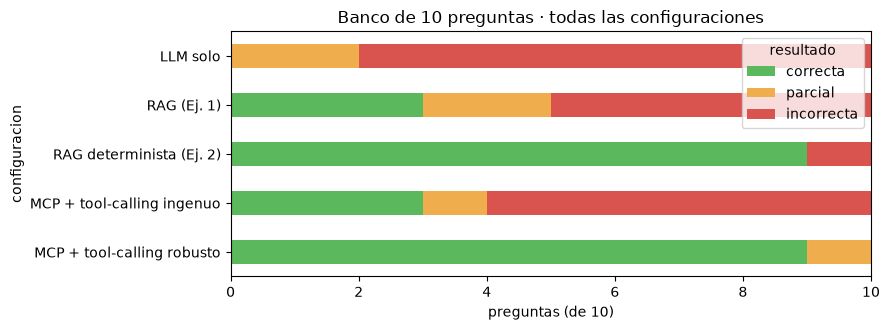

In [9]:
CONFIGURACIONES = {"llm_solo": "LLM solo", "rag_vectorial": "RAG (Ej. 1)", "rag_determinista": "RAG determinista (Ej. 2)",
                   "mcp_ingenuo": "MCP + tool-calling ingenuo", "mcp_robusto": "MCP + tool-calling robusto"}
todos = pd.concat([pd.read_csv(cmp.SALIDAS / f"resultados_{c}.csv").assign(configuracion=n)
                   for c, n in CONFIGURACIONES.items()])

tablero = (todos.groupby(["configuracion", "resultado"]).size().unstack(fill_value=0)
           .reindex(index=CONFIGURACIONES.values(), columns=["correcta", "parcial", "incorrecta"], fill_value=0))
tablero.to_csv(cmp.SALIDAS / "tablero_final.csv")
display(tablero)

ax = tablero.plot.barh(stacked=True, color=["#5cb85c", "#f0ad4e", "#d9534f"], figsize=(9, 3.4))
ax.set_xlabel("preguntas (de 10)"); ax.set_title("Banco de 10 preguntas · todas las configuraciones"); ax.invert_yaxis()
plt.tight_layout(); plt.savefig("../salidas/tablero_final.png", dpi=120); plt.show()

In [10]:
# ¿Qué tipo de pregunta resuelve cada configuración? (✔ correcta · ~ parcial · ✘ incorrecta)
simbolo = {"correcta": "✔", "parcial": "~", "incorrecta": "✘"}
matriz = todos.assign(r=todos.resultado.map(simbolo)).pivot(index=["id", "tipo"], columns="configuracion", values="r")
matriz = matriz[list(CONFIGURACIONES.values())]
matriz.to_csv(cmp.SALIDAS / "matriz_por_pregunta.csv")
matriz

,configuracion,LLM solo,RAG (Ej. 1),RAG determinista (Ej. 2),MCP + tool-calling ingenuo,MCP + tool-calling robusto
id,tipo,,,,,
1,descriptiva,✘,✔,✔,✔,✔
2,filtro,~,~,✔,✔,✔
3,conteo,✘,✘,✔,✘,✔
4,agregacion,✘,✘,✔,✘,✔
5,ranking,~,✘,✔,✘,✔
6,opinion,✘,✘,✘,✘,~
7,puntual,✘,✔,✔,✘,✔
8,relacional,✘,~,✔,~,✔
9,ranking,✘,✘,✔,✘,✔


## 7. Experimenta

Hacer preguntas propias al agente robusto y observar la traza: qué decidió el router, si intervino el
LLM, qué tool se llamó y con qué argumentos.

In [11]:
for p in ["¿Qué productos están en riesgo?",
          "¿Qué drones cuestan menos de 5000 soles?",
          "¿Qué opinan los clientes de la PlayStation 5?",
          "¿Cuál es el producto mejor calificado de la categoría Audio?"]:
    mostrar_traza(await robusto.preguntar(p))

❓ ¿Qué productos están en riesgo?
   · router               {"intencion": "productos_en_riesgo", "confianza": 1.0}
   · call_tool            {"tool": "consultar_ontologia", "args": {"pregunta": "¿Qué productos están en riesgo?"}, "error_mcp": false, "resultado": "{'determinista': True, 'intencion': 'productos_en_riesgo'
🤖 Productos en riesgo (calificación < 3 y reseñas de entrega negativas): 6. Samsung Galaxy A15 128GB (1.8★); Sony Bravia X75L 65 pulgadas (2.0★); HP Omen 16 RTX 4060 (2.0★); JBL Flip 6 (2.8★); Xiaomi Redmi Note 13 Pro 256GB (2.8★); TCL 50 pulgadas 4K Google TV (2.8★).  (0.39 s)

❓ ¿Qué drones cuestan menos de 5000 soles?
   · router               {"intencion": "productos_subcategoria_precio_max", "confianza": 0.91}
   · call_tool            {"tool": "consultar_ontologia", "args": {"pregunta": "¿Qué drones cuestan menos de 5000 soles?"}, "error_mcp": false, "resultado": "{'determinista': True, 'intencion': 'productos_s
🤖 Productos de Drones con precio menor a S/ 5000: 1.

In [12]:
# Escribe aquí tu pregunta
mostrar_traza(await robusto.preguntar("¿Cuánto cuesta el Apple Watch Ultra 2?"))

❓ ¿Cuánto cuesta el Apple Watch Ultra 2?
   · router               {"intencion": "productos_subcategoria_precio_max", "confianza": 0.54}
   · llm_intento_1        {"salida": "<tool_call>\n{\"name\": \"buscar_productos\", \"arguments\": {\"consulta\": \"Apple Watch Ultra 2\", \"categoria\": \"marca\", \"precio_max\": 500}}\n</tool_call>"}
   · call_tool            {"tool": "buscar_productos", "args": {"consulta": "Apple Watch Ultra 2"}, "error_mcp": false, "resultado": "[{'nombre': 'Apple Watch Ultra 2', 'categoria': 'Wearables y Fitness', '
🤖 El Apple Watch Ultra 2 cuesta $3999.  (2.12 s)



In [13]:
await ingenuo.cerrar()
await robusto.cerrar()

## Discusión

- **Cada pieza resuelve un tipo de pregunta.** El RAG resuelve lo descriptivo y las opiniones; la
  ontología con RAG determinista resuelve conteos, agregaciones, rankings y relaciones; MCP aporta los
  datos en vivo y una forma estándar de conectar todo. Ninguna sola cubre el banco completo.
- **Con un modelo pequeño, la fiabilidad viene de la arquitectura y no del modelo.** El agente
  robusto usa el LLM solo donde aporta (elegir entre búsquedas y redactar sobre texto) y deja al código
  determinista las decisiones que se pueden tomar con reglas.
- **El patrón se mantiene con modelos grandes:** un LLM más capaz equivoca menos tools, pero el
  router determinista, la validación por esquema y las respuestas exactas con plantilla siguen
  aportando trazabilidad, menor costo y menor latencia.
- **Limitaciones:** la evaluación busca términos esperados, así que una respuesta con el dato
  correcto pero otra redacción puede contar como parcial. El banco tiene solo 10 preguntas.

## Relación con CRISP-ML(Q)

| Fase | En este asistente |
|---|---|
| Comprensión del negocio y de los datos | preguntas reales de clientes y analistas; datos scrapeados de la tienda |
| Preparación de datos | documentos y metadatos (RAG), tripletas y validación SHACL (ontología) |
| Modelado | embeddings + ChromaDB, intenciones + SPARQL, LLM con tools |
| Evaluación | banco de preguntas con respuestas esperadas; métricas de exactitud, repetibilidad y tool adecuada |
| Despliegue | MCP server reutilizable por cualquier host |
| Monitoreo y mantenimiento | log del server, re-scraping y re-indexación, revisión de preguntas que caen al *fallback* |